# Formal mexcuda versus A-T timing on NGSolve

The mdx GPU machine reached through the `NGSolve` SSH alias has an NVIDIA A100-SXM4-40GB. This study uses an idle host, four NGSolve threads and one BLAS/MATLAB computational thread. It compares complete three-stage CLN calculations on four identical curved-mesh cohorts, including setup, operator uploads, load assembly, all seven recovery steps, Python–MATLAB transfers and unchanged residual checks.

The native runtime is the released Radia 5.2.3 wheel with NGSolve 6.2.2607. CLN producers are repository source, identified by their saved hashes; merging source does not itself release a package. The compiled MEX is the same hash-verified artifact built on 100. See [scope and timing definitions](MEXCUDA_TIMING.md), [bulk implementation](BULK_SCALAR_CLN.md) and [accuracy comparison limits](ACCURACY_REVIEW.md).


In [1]:
import json, statistics
from pathlib import Path
from IPython.display import Markdown, display
import numpy as np
import matplotlib.pyplot as plt
base=Path('docs/data') if Path('docs/data').exists() else Path('data')
data,host,initialization=[json.loads((base/name).read_text()) for name in
    ('mexcuda_cln_timing.json','mexcuda_timing_host.json','mexcuda_initialization.json')]
assert all(d['complete'] for d in (data,host,initialization))
display(Markdown('Runtime: `'+json.dumps(data['runtime'])+'`'))
display(Markdown('GPU: `'+json.dumps(host['preflight_gpu'])+'`'))
def table(header,rows):
    display(Markdown('| '+' | '.join(header)+' |\n|'+ '|'.join(['---']*len(header))+'|\n'+
                     '\n'.join('| '+' | '.join(map(str,r))+' |' for r in rows)))
def runs(c,route):return [r for r in c['repeats'] if r['route']==route and r['repeat']>0]
def median(c,route):return statistics.median(r['seconds'] for r in runs(c,route))
labels=[f"p={c['order']}, {c['maxh']*1000:g} mm" for c in data['cohorts']]


Runtime: `{"host": "NGSolve", "python": "3.12.10", "ngsolve": "6.2.2607", "numpy": "2.5.2", "radia": "5.2.3", "threads": 4, "blas_pools": [{"user_api": "blas", "internal_api": "openblas", "num_threads": 1, "prefix": "libscipy_openblas", "version": "0.3.34.0.0", "threading_layer": "pthreads", "architecture": "SkylakeX"}, {"user_api": "blas", "internal_api": "openblas", "num_threads": 1, "prefix": "openblas", "version": "0.3.33", "threading_layer": "pthreads", "architecture": "Haswell"}, {"user_api": "blas", "internal_api": "mkl", "num_threads": 1, "prefix": "mkl_rt", "version": "2026.1-Product", "threading_layer": "intel"}, {"user_api": "blas", "internal_api": "openblas", "num_threads": 1, "prefix": "libscipy_openblas", "version": "0.3.31.dev", "threading_layer": "pthreads", "architecture": "SkylakeX"}, {"user_api": "openmp", "internal_api": "openmp", "num_threads": 18, "prefix": "libiomp", "version": null}]}`

GPU: `{"name": "NVIDIA A100-SXM4-40GB", "driver": "591.59", "total_mib": 40960, "used_mib": 10, "utilization_percent": 0}`

## Complete recursion, warmed median and observed range

Each route has one first observation and three warmed observations. Execution order reverses on alternating repeats. Mesh construction, point sampling, route-object cleanup after return and cross-route comparison are outside the reported solver time; all physical acceptance checks are inside. First observations are not cold-boot timings, and only the first cohort shares the initial Engine startup. Raw observations are retained.


| Cohort | Original A-T [s] | Condensed A-T [s] | CPU bulk V/Phi [s] | mexcuda V/Phi [s] | A-T / MEX | CPU bulk / MEX |
|---|---|---|---|---|---|---|
| p=2, 3 mm | 1.265 [1.189, 1.452] | 0.952 [0.894, 1.016] | 2.685 [2.683, 2.702] | 2.553 [2.520, 2.576] | 0.495 | 1.051 |
| p=3, 3 mm | 3.562 [3.113, 4.145] | 2.294 [2.282, 2.377] | 6.780 [6.767, 6.922] | 6.209 [6.201, 6.215] | 0.574 | 1.092 |
| p=3, 2 mm | 8.816 [8.675, 9.114] | 6.619 [6.543, 6.761] | 22.133 [21.842, 22.136] | 17.621 [17.580, 17.696] | 0.500 | 1.256 |
| p=4, 3 mm | 8.741 [8.383, 8.792] | 4.599 [4.550, 4.787] | 17.216 [17.205, 17.416] | 15.306 [15.295, 15.371] | 0.571 | 1.125 |

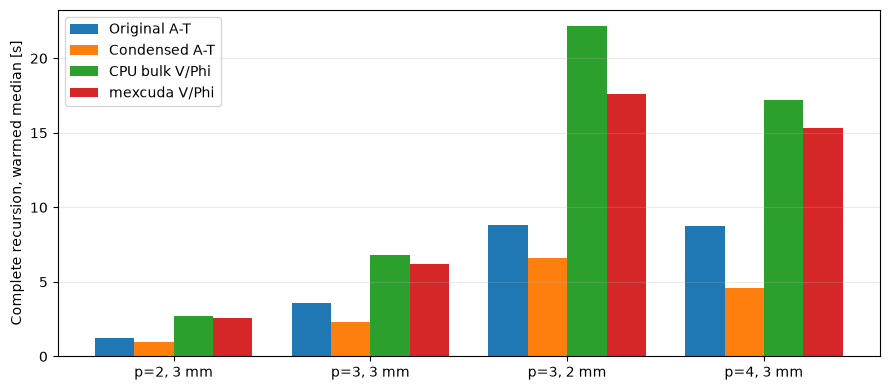

In [2]:
rows=[]
for label,c in zip(labels,data['cohorts']):
    row=[label]
    for route in ('original','condensed','scalar-bulk','scalar-mexcuda'):
        values=[r['seconds'] for r in runs(c,route)]
        row.append(f'{statistics.median(values):.3f} [{min(values):.3f}, {max(values):.3f}]')
    row.extend([f"{median(c,'original')/median(c,'scalar-mexcuda'):.3f}",
                f"{median(c,'scalar-bulk')/median(c,'scalar-mexcuda'):.3f}"])
    rows.append(row)
table(['Cohort','Original A-T [s]','Condensed A-T [s]','CPU bulk V/Phi [s]','mexcuda V/Phi [s]','A-T / MEX','CPU bulk / MEX'],rows)
fig,ax=plt.subplots(figsize=(9,4))
x=np.arange(len(labels));width=.2
for i,(route,name) in enumerate(zip(('original','condensed','scalar-bulk','scalar-mexcuda'),('Original A-T','Condensed A-T','CPU bulk V/Phi','mexcuda V/Phi'))):
    ax.bar(x+(i-1.5)*width,[median(c,route) for c in data['cohorts']],width,label=name)
ax.set_xticks(x,labels);ax.set_ylabel('Complete recursion, warmed median [s]')
ax.legend();ax.grid(axis='y',alpha=.25);fig.tight_layout();plt.show()


## Transfer and recovery accounting

Operator upload is already included in setup and total recursion. Its setup-call wall time includes array conversion, MATLAB bridge, device allocation and upload. It is counted once per T/A recovery object, not once per stage. Per-step MEX wall time includes target upload, FP64 projection, fit reductions, coefficient download and conversion/bridge overhead. The bridge figure is a wall-time remainder; projection/fit clocks include host launches and synchronization, not pure CUDA-event kernel times. These are nested timings: do not add them again to the total recursion time. FE assembly, scalar solves and integrated residual checks remain on CPU.


In [3]:
rows=[]
for label,c in zip(labels,data['cohorts']):
    records=runs(c,'scalar-mexcuda')
    med=lambda fn:statistics.median(fn(r) for r in records)
    keys=('device_upload_seconds','mex_internal_projection_seconds','curl_check_seconds','device_download_seconds','matlab_bridge_seconds')
    parts=[med(lambda r,k=k:sum(s[k] for s in r['solves'])) for k in keys]
    rows.append([label,f"{med(lambda r:r['setup_seconds']):.3f}",
        f"{med(lambda r:sum(s['mex_setup_transfer_seconds'] for s in r['solves'][:2])):.3f}",
        *[f'{v:.4f}' for v in parts],
        f"{med(lambda r:sum(s['mex_call_seconds'] for s in r['solves'])):.4f}",
        f"{med(lambda r:r['seconds']-r['setup_seconds']-sum(s['mex_call_seconds'] for s in r['solves'])):.4f}"])
table(['Cohort','Setup [s]','Operator setup calls [s]','Targets H2D [s]','Projection [s]','Fit checks [s]','Values D2H [s]','Bridge [s]','MEX wall [s]','Remaining recursion [s]'],rows)


| Cohort | Setup [s] | Operator setup calls [s] | Targets H2D [s] | Projection [s] | Fit checks [s] | Values D2H [s] | Bridge [s] | MEX wall [s] | Remaining recursion [s] |
|---|---|---|---|---|---|---|---|---|---|
| p=2, 3 mm | 0.892 | 0.046 | 0.0004 | 0.2219 | 0.0232 | 0.0002 | 0.0306 | 0.2763 | 1.3836 |
| p=3, 3 mm | 2.354 | 0.157 | 0.0005 | 0.3168 | 0.0314 | 0.0004 | 0.0311 | 0.3802 | 3.4742 |
| p=3, 2 mm | 6.713 | 0.457 | 0.0006 | 0.9393 | 0.0714 | 0.0009 | 0.0428 | 1.0549 | 9.8120 |
| p=4, 3 mm | 6.705 | 0.496 | 0.0006 | 0.9586 | 0.0707 | 0.0007 | 0.0380 | 1.0689 | 7.5334 |

## Initialization, first observations and amortization

Four separate fresh MATLAB processes measure Engine launch, configuration, GPU context initialization, metadata queries and shutdown. Filesystem/driver caches may be warm; this is not a machine-cold experiment. Python/module import and mesh construction are excluded common setup costs. The initialization-plus-warmed calculation below is an explicitly recombined estimate for a fresh session, not an independently measured cold solve. A session shared across N complete CLN runs pays initialization once. Shutdown is reported separately.


In [4]:
keys=('engine_start_seconds','configuration_seconds','device_start_seconds','initialization_seconds','quit_call_seconds','shutdown_seconds')
table(['Fresh process',*keys],[[r['repeat'],*[f'{r[k]:.4f}' for k in keys]] for r in initialization['runs']])
startup=statistics.median(r['initialization_seconds'] for r in initialization['runs'])
rows=[]
for label,c in zip(labels,data['cohorts']):
    first=lambda route:next(r['seconds'] for r in c['repeats'] if r['route']==route and r['repeat']==0)
    warm=median(c,'scalar-mexcuda')
    rows.append([label,f"{first('original'):.3f}",f"{first('scalar-mexcuda'):.3f}",
        *[f'{warm+startup/n:.3f}' for n in (1,10,100)]])
table(['Cohort','First A-T call [s]','First MEX call [s]','Init + warm, N=1 [s/run]','N=10 [s/run]','N=100 [s/run]'],rows)


| Fresh process | engine_start_seconds | configuration_seconds | device_start_seconds | initialization_seconds | quit_call_seconds | shutdown_seconds |
|---|---|---|---|---|---|---|
| 0 | 5.6470 | 0.1291 | 0.3847 | 6.4533 | 0.0042 | 2.8558 |
| 1 | 4.5512 | 0.3954 | 0.4053 | 5.3616 | 0.0033 | 2.5761 |
| 2 | 4.8295 | 0.4041 | 0.3726 | 5.6114 | 0.0033 | 2.5727 |
| 3 | 4.5929 | 0.4147 | 0.3773 | 5.3901 | 0.0031 | 2.5945 |

| Cohort | First A-T call [s] | First MEX call [s] | Init + warm, N=1 [s/run] | N=10 [s/run] | N=100 [s/run] |
|---|---|---|---|---|---|
| p=2, 3 mm | 1.765 | 2.740 | 8.054 | 3.103 | 2.608 |
| p=3, 3 mm | 3.166 | 6.288 | 11.709 | 6.759 | 6.264 |
| p=3, 2 mm | 8.512 | 17.675 | 23.122 | 18.171 | 17.676 |
| p=4, 3 mm | 8.627 | 15.417 | 20.806 | 15.856 | 15.361 |

In [5]:
errors=[r for c in data['cohorts'] for r in c['comparisons'] if r['route']=='scalar-mexcuda']
coefficient=max(abs(v) for r in errors for v in r['relative_coefficients'])
field=max(v for r in errors for v in r['volume_relative_field_errors'])
residual=max(s['recovered_original_residual'] for c in data['cohorts'] for r in c['repeats'] if r['route']=='scalar-mexcuda' for s in r['solves'])
table(['Max coefficient relative difference','Max volume-vector relative difference','Max recovered original-equation residual'],[[f'{coefficient:.5e}',f'{field:.5e}',f'{residual:.5e}']])
table(['Idle preflight CPU fraction','Foreign-job monitor samples','Foreign jobs observed'],[[host['preflight_cpu_busy_fraction'],len(host['foreign_compute_job_samples']),sum(len(v) for v in host['foreign_compute_job_samples'])]])


| Max coefficient relative difference | Max volume-vector relative difference | Max recovered original-equation residual |
|---|---|---|
| 1.21173e-10 | 5.34785e-09 | 4.19971e-10 |

| Idle preflight CPU fraction | Foreign-job monitor samples | Foreign jobs observed |
|---|---|---|
| 0.029171528588098017 | 24 | 0 |

## Interpretation and limits

Use the measured complete-recursion ratios, including setup and transfers, to decide whether this GPU implementation wins. Faster local kernels do not establish a faster complete CLN method. Standalone MATLAB startup further increases the cost for short sessions. These results cover only constant-material internal round wire, zero expansion shift, three stages and the recorded meshes. They do not establish a universal A-T/V/Phi ordering, large-mesh scaling or a GPU-memory advantage.

The host monitor checks for foreign Python/MATLAB/pytest/nvcc processes every 30 seconds; short jobs between samples and hypervisor contention cannot be ruled out. The preflight CPU fraction and GPU utilization gate passed. The public JSON retains all timings and source identities; exact binary, runtime freeze, command records and raw diagnostics remain in private durable laboratory storage. This addition is Codex self-review, not independent scientific acceptance.
